In [ ]:
%%bash
pip install git+https://github.com/ishikota/PyPokerEngine.git #Git Repository

  Cloning https://github.com/ishikota/PyPokerEngine.git to /tmp/pip-req-build-xvm__1zv
  Resolved https://github.com/ishikota/PyPokerEngine.git to commit a52a048a15da276005eca4acae96fb6eeb4dc034
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command git clone --filter=blob:none --quiet https://github.com/ishikota/PyPokerEngine.git /tmp/pip-req-build-xvm__1zv


In [ ]:
from pypokerengine.players import BasePokerPlayer
from pypokerengine.api.game import setup_config, start_poker
from pypokerengine.utils.card_utils import gen_cards, estimate_hole_card_win_rate
import random

#Types of players (Non model)

class RandomPlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):
        actions = {a['action']: a for a in valid_actions} #Cannot raise if out of chips
        action = random.choice(list(actions.keys()))

        if action == 'raise':

            max_amount = actions[action]['amount']['max']
            min_amount = actions[action]['amount']['min']

            if random.random() < 0.5:
                return action, min_amount #Should prevent random from raising to high too often

            max_val = max(min_amount, max_amount - 300)
            ammount = random.randint(min_amount, max_val)

            ammount = max(ammount, min_amount) #In case max amount-300 is less than 0
            return action, ammount
        else:
            return action, actions[action]['amount'] #Call or fold

    def receive_game_start_message(self, game_info):
        pass

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass


class HonestPlayer(BasePokerPlayer): #Modified version of HonestPlayer from Github. Instead of calling above a certain win threshold, this player will raise according to how good their hand is

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        if win_rate >= 1.5 / self.nb_player: #Raise when hand is strong
            if 'raise' in actions:
                return 'raise', actions['raise']['amount']['min']
            else:
                return 'call', actions['call']['amount']
        elif win_rate >= 0.8 / self.nb_player: #Call if hand okay
            return 'call', actions['call']['amount']
        else:
            return 'fold', actions['fold']['amount']

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

class BluffPlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']
        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        if win_rate < 0.8 / self.nb_player: #Bluff weak hands to scare off other players
            if 'raise' in actions:
                return 'raise', actions['raise']['amount']['min']
            else:
                return 'call', actions['call']['amount']
        else:
            return 'call', actions['call']['amount'] #Call on good hands

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

class PassivePlayer(BasePokerPlayer):

    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=100,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        actions = {a['action']: a for a in valid_actions}

        #Fold unless hand is excellent
        if win_rate >= 2.0 / self.nb_player:
            return 'call', actions['call']['amount']
        else:
            return 'fold', actions['fold']['amount']

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

    def receive_round_start_message(self, round_count, hole_card, seats):
        pass

    def receive_street_start_message(self, street, round_state):
        pass

    def receive_game_update_message(self, action, round_state):
        pass

    def receive_round_result_message(self, winners, hand_info, round_state):
        pass

#To Do - Add more player types (No more than 10)

#Folder - Calls unless there is a raise, in which case this player panics and folds unless hand is excellent

#Tilt - Plays normally until they start losing chips, in which case, they start betting and bluffing aggressively

#Panic - Plays aggressivly until they start losing chips, in which case, they start to play more carfeully


opponents_pool = [
    ("Honest", HonestPlayer()),
    ("Bluff", BluffPlayer()),
    ("Random", RandomPlayer()),
    ("Passive", PassivePlayer()),
]

In [ ]:
import numpy as np
from collections import defaultdict
from pypokerengine.players import BasePokerPlayer
from pypokerengine.utils.card_utils import gen_cards, estimate_hole_card_win_rate

#WIP
class Agent(BasePokerPlayer):

    def __init__(self, alpha=0.1, gamma=0.75, epsilon=0.25, min_epsilon=0.05, epsilon_decay=0.80, nb_simulation=500): #Try some different alpha, gamma, and epsilon values

        super().__init__()

        self.alpha = alpha
        self.initial_alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.epsilon_decay = epsilon_decay
        self.nb_simulation = nb_simulation
        self.round_count = 0

        #state -> action -> value
        self.q_table = defaultdict(lambda: {"fold": 0.0, "call": 0.0, "raise": 0.0})
        self.opponent_raises = defaultdict(int)
        self.last_state = None
        self.last_action = None
        self.initial_chips = 0
        self.last_chips = 0

    #Wip
    def _get_state(self, win_rate, round_state):

        #Covert win rate ranges to discrete states
        if win_rate < 0.4:
            w = 0  #Weak hand
        elif win_rate < 0.55:
            w = 1  #Decent hand
        elif win_rate < 0.7:
            w = 2  #Good hand
        elif win_rate < 0.85:
            w = 3  #Great hand
        else:
            w = 4  #Amazing hand

        table = round_state['street'] #State of the cards on the table

        aggression = sum(self.opponent_raises.values())

        #Need to differiate opponents more. This is just table aggression

        #Keep track of old actions? Should probably not fold if just raised unless there is a very high raise

        #Want model to prioitise small safe gains over going to 5000 one round and 0 every other round

        #aggression = min(3, aggression)

        return (w, table, aggression)

    #Wip
    def declare_action(self, valid_actions, hole_card, round_state):

        community_card = round_state['community_card']

        win_rate = estimate_hole_card_win_rate(
            nb_simulation=self.nb_simulation,
            nb_player=self.nb_player,
            hole_card=gen_cards(hole_card),
            community_card=gen_cards(community_card)
        )

        state = self._get_state(win_rate, round_state) #Determine current state

        actions = {a['action']: a for a in valid_actions}

        #WIP
        if np.random.rand() < self.epsilon: #Try random option epsilon percent of the time
            chosen_action_name = np.random.choice(list(actions.keys()))
        else: #Otherwise, choose option according to q_value
            q_vals = self.q_table[state]
            legal_q = {a: q_vals[a] for a in actions.keys()}
            chosen_action_name = max(legal_q, key=legal_q.get)

        self.last_state = state
        self.last_action = chosen_action_name

        action_detail = actions[chosen_action_name]
        if chosen_action_name == 'raise':
            amount = action_detail['amount']['min']
        else:
            amount = action_detail['amount']

        return chosen_action_name, amount

    def receive_game_start_message(self, game_info):
        self.nb_player = game_info['player_num']

        #Record other players number for later diffentiation?

        for player in game_info['seats']:
            if player['uuid'] == self.uuid:
                self.initial_chips = player['stack'] #Set chips to starting value
                self.last_chips = self.initial_chips

    #Wip
    def receive_round_start_message(self, round_count, hole_card, seats):
        self.round_count += 1 #Update round count
        self.opponent_raises.clear() #Clear opponent raises

    def receive_street_start_message(self, street, round_state):
        pass

    #Wip
    def receive_game_update_message(self, action, round_state):
        if action['player_uuid'] != self.uuid and action['action'] == 'raise':
            self.opponent_raises[action['player_uuid']] += 1

    def receive_round_result_message(self, winners, hand_info, round_state):

        current_chips = 0

        for player in round_state['seats']:

            if player['uuid'] == self.uuid:
                current_chips = player['stack']
                break

        r = (current_chips - self.last_chips) / 10.0 #r(s) = how many chips gained since last round (Divided by 10 to limit dangerous play) #Maybe divide even more, performance is poor

        if self.last_state is not None and self.last_action is not None:

            q = self.q_table[self.last_state][self.last_action]

            q = 0.0
            for action in self.q_table[self.last_state]:
                max_q = max(q, self.q_table[self.last_state][action])
                #print(self.q_table[self.last_state][action])

            q = q + self.alpha * (r + (self.gamma * max_q) - q) #q = q + a(r(s) + y(max(q(s', a))) - q)

            self.q_table[self.last_state][self.last_action] = q #q(s, a) = q

        self.last_chips = current_chips

        #Wip
        #Less random chance as model learns and a policy is developed
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)
        #self.alpha = max(0.01, self.initial_alpha / (1.0 + 0.01 * self.round_count))

In [ ]:
import random
from pypokerengine.api.game import setup_config, start_poker

MAX_ROUNDS = 50
INITIAL_STACK = 1000
SMALL_BLIND_AMOUNT = 10

learned_Agent = Agent()

training_rounds = 25 #6 Minutes

for game in range(training_rounds):

    selected_opponents = random.sample(opponents_pool, 2)
    config = setup_config(max_round=MAX_ROUNDS, initial_stack=INITIAL_STACK, small_blind_amount=SMALL_BLIND_AMOUNT)
    config.register_player(name="Agent", algorithm=learned_Agent)

    for name, obj in selected_opponents:
        config.register_player(name=name, algorithm=obj)

    start_poker(config, verbose=0)

    if game == 0 or game == (training_rounds-1) or (game+1) % 10 == 0: #Print every 10 rounds so you can know approx how far into training (As well as first and last rounds) Change value from 10 to a higher number if doing 500+ tests
        opponent_names = [name for name, _ in selected_opponents]
        print(f"Game {game+1}/{training_rounds} finished - Opponents: {opponent_names[0], opponent_names[1]} - Chips: {learned_Agent.last_chips}")

Game 1/25 finished - Opponents: ('Bluff', 'Honest') - Chips: 690
Game 10/25 finished - Opponents: ('Honest', 'Passive') - Chips: 1450
Game 20/25 finished - Opponents: ('Passive', 'Random') - Chips: 2578
Game 25/25 finished - Opponents: ('Honest', 'Passive') - Chips: 970


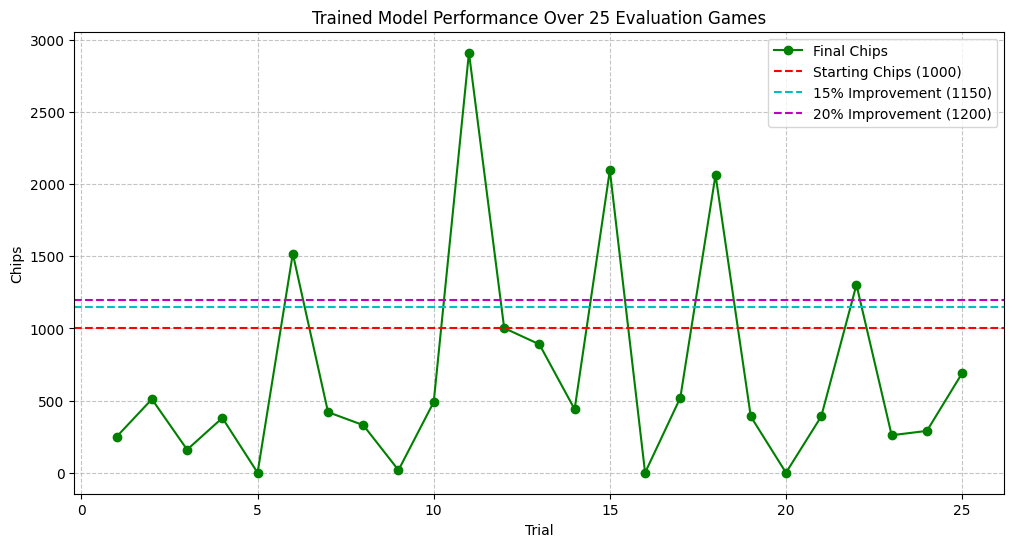

In [ ]:
import matplotlib.pyplot as plt
import random
from pypokerengine.api.game import setup_config, start_poker

chips = []

game_count = 25 #5 minutes

#Turn off learning? Pure q value
learned_Agent.epsilon = 0.0
learned_Agent.alpha = 0.0

for game in range(game_count):
    opponents = random.sample(opponents_pool, 2)

    #To Do - Display opponents per round so we can see which opponents the Agent struggles with

    config = setup_config(max_round=MAX_ROUNDS, initial_stack=INITIAL_STACK, small_blind_amount=SMALL_BLIND_AMOUNT)
    config.register_player(name="Agent", algorithm=learned_Agent)

    for name, alg in opponents:
        config.register_player(name=name, algorithm=alg)

    start_poker(config, verbose=0)

    chips.append(learned_Agent.last_chips)


plt.figure(figsize=(12, 6))
plt.plot(range(1, game_count+1), chips, marker='o', linestyle='-', color='g', label='Final Chips')
plt.axhline(y=1000, color='r', linestyle='--', label='Starting Chips (1000)')
plt.axhline(y=1150, color='c', linestyle='--', label='15% Improvement (1150)')
plt.axhline(y=1200, color='m', linestyle='--', label='20% Improvement (1200)')
plt.title("Trained Model Performance Over " + str(game_count) + " Evaluation Games")
plt.xlabel("Trial")
plt.ylabel("Chips")
plt.grid(True, linestyle='--', alpha=0.75)
plt.legend()
plt.show()

#To Do - Calculate average chip improvement over games
#Should probably do in another cell so you don't have to run the eval games every time

